In [1]:
from pathlib import Path
import os
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dataset generation

Run the cells in 

```
Binding-Problem-Brown/search-dataset/minimal_pair_swap.ipynb
```

and 

```
Binding-Problem-Brown/search-dataset/search_counterfact_dataset_gen.ipynb
```

to generate datasets

# Behavioral-Benchmark

## Conjunctive and Disjunctive Search

Run 
```
cd Binding-Problem-Brown/scripts
```

then

```
python benchmark.py \
  --dataset VS_CF \
  --conditions disjunctive conjunctive \
  --prompt_type binary \
  --out_path ../Results/qwen_disjunctive_conjunctive_all_distractors.csv
```

***Estimated to take ~ 10 min***

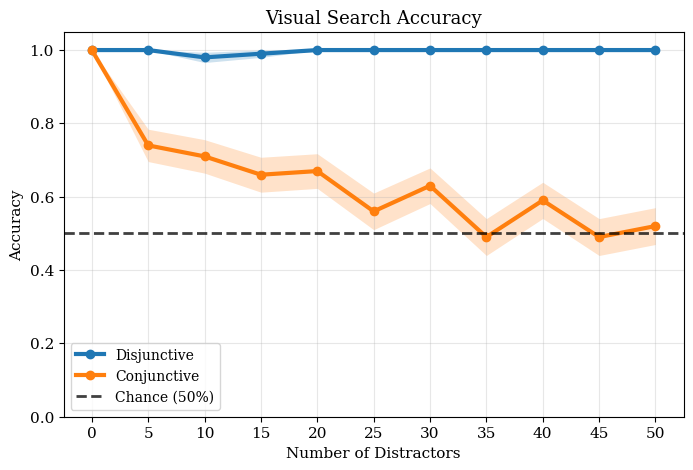

In [6]:
# Visualization

# ==================================================
# LOAD RESULTS
# ==================================================

INPUT_CSV = Path(
    "../Results/qwen_disjunctive_conjunctive_all_distractors.csv"
)

df = pd.read_csv(INPUT_CSV).copy()

# Keep only the two conditions of interest
df = df[df["condition"].isin(["disjunctive", "conjunctive"])].copy()

# Handle booleans robustly if pandas loaded them as strings
if df["correct"].dtype == object:
    df["correct"] = (
        df["correct"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )

df = df.dropna(subset=["correct", "num_distractors"])

# ==================================================
# SUMMARIZE
# ==================================================

summary = (
    df.groupby(["condition", "num_distractors"])["correct"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

summary["sem"] = summary["std"] / np.sqrt(summary["count"])
summary["sem"] = summary["sem"].fillna(0)

# ==================================================
# PLOT
# ==================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(8, 5))

styles = {
    "disjunctive": {"label": "Disjunctive", "color": "#1f77b4"},
    "conjunctive": {"label": "Conjunctive", "color": "#ff7f0e"},
}

for condition, style in styles.items():
    condition_df = (
        summary[summary["condition"] == condition]
        .sort_values("num_distractors")
    )

    x = condition_df["num_distractors"]
    y = condition_df["mean"]
    sem = condition_df["sem"]

    ax.plot(
        x, y,
        marker="o",
        linewidth=3,
        markersize=6,
        color=style["color"],
        label=style["label"],
    )

    ax.fill_between(
        x,
        (y - sem).clip(lower=0),
        (y + sem).clip(upper=1),
        color=style["color"],
        alpha=0.22,
        linewidth=0,
    )

ax.axhline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=2,
    alpha=0.75,
    label="Chance (50%)",
)

ax.set_title("Visual Search Accuracy")
ax.set_xlabel("Number of Distractors")
ax.set_ylabel("Accuracy")
ax.set_xticks(sorted(df["num_distractors"].unique()))
ax.set_ylim(0, 1.05)

ax.grid(True, alpha=0.3)
ax.legend(loc="lower left", frameon=True)


plt.show()


## Minimal Pair Datset (Verify that accuracy is 100%)

Run 
```
cd Binding-Problem-Brown/scripts
```

then

```
python benchmark.py \
  --dataset MP_S \
  --prompt_type binary \
  --out_path ../Results/qwen_minimal_pair_swap_benchmark.csv
```

***Estimated to take ~ 1 min***

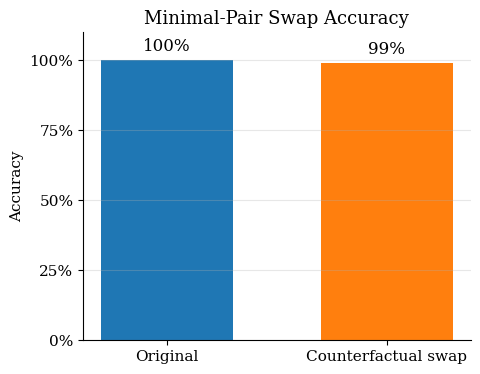

In [9]:
INPUT_CSV = Path("../Results/qwen_minimal_pair_swap_benchmark.csv")

df = pd.read_csv(INPUT_CSV)

summary = (
    df.groupby("condition")["correct"]
    .mean()
    .mul(100)
    .reindex(["original", "counterfactual_swap"])
)

labels = {
    "original": "Original",
    "counterfactual_swap": "Counterfactual swap",
}

fig, ax = plt.subplots(figsize=(5, 4))

bars = ax.bar(
    [labels[c] for c in summary.index],
    summary.values,
    color=["#1f77b4", "#ff7f0e"],
    width=0.6,
)

for bar, accuracy in zip(bars, summary.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 2,
        f"{accuracy:.0f}%",
        ha="center",
        va="bottom",
        fontsize=12,
    )

ax.set_title("Minimal-Pair Swap Accuracy")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.show()


# Causal Tracing (Patching Disjunctive -> Conjunctive)

cd into the scripts directory then run:

```
python layer_token_component_causal_tracing.py \
  --source_condition disjunctive \
  --target_condition conjunctive \
  --source_distractors 40 \
  --target_distractors 40 \
  --components attention,mlp \
  --token_offsets=-19:0 \
  --layers all \
  --window_size 5 \
  --pair_filter all \
  --out_path ../Results/disj40_to_conj40_layer_token_components_w5.csv
```

***Likely to take ~1-2 hours to run***

/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


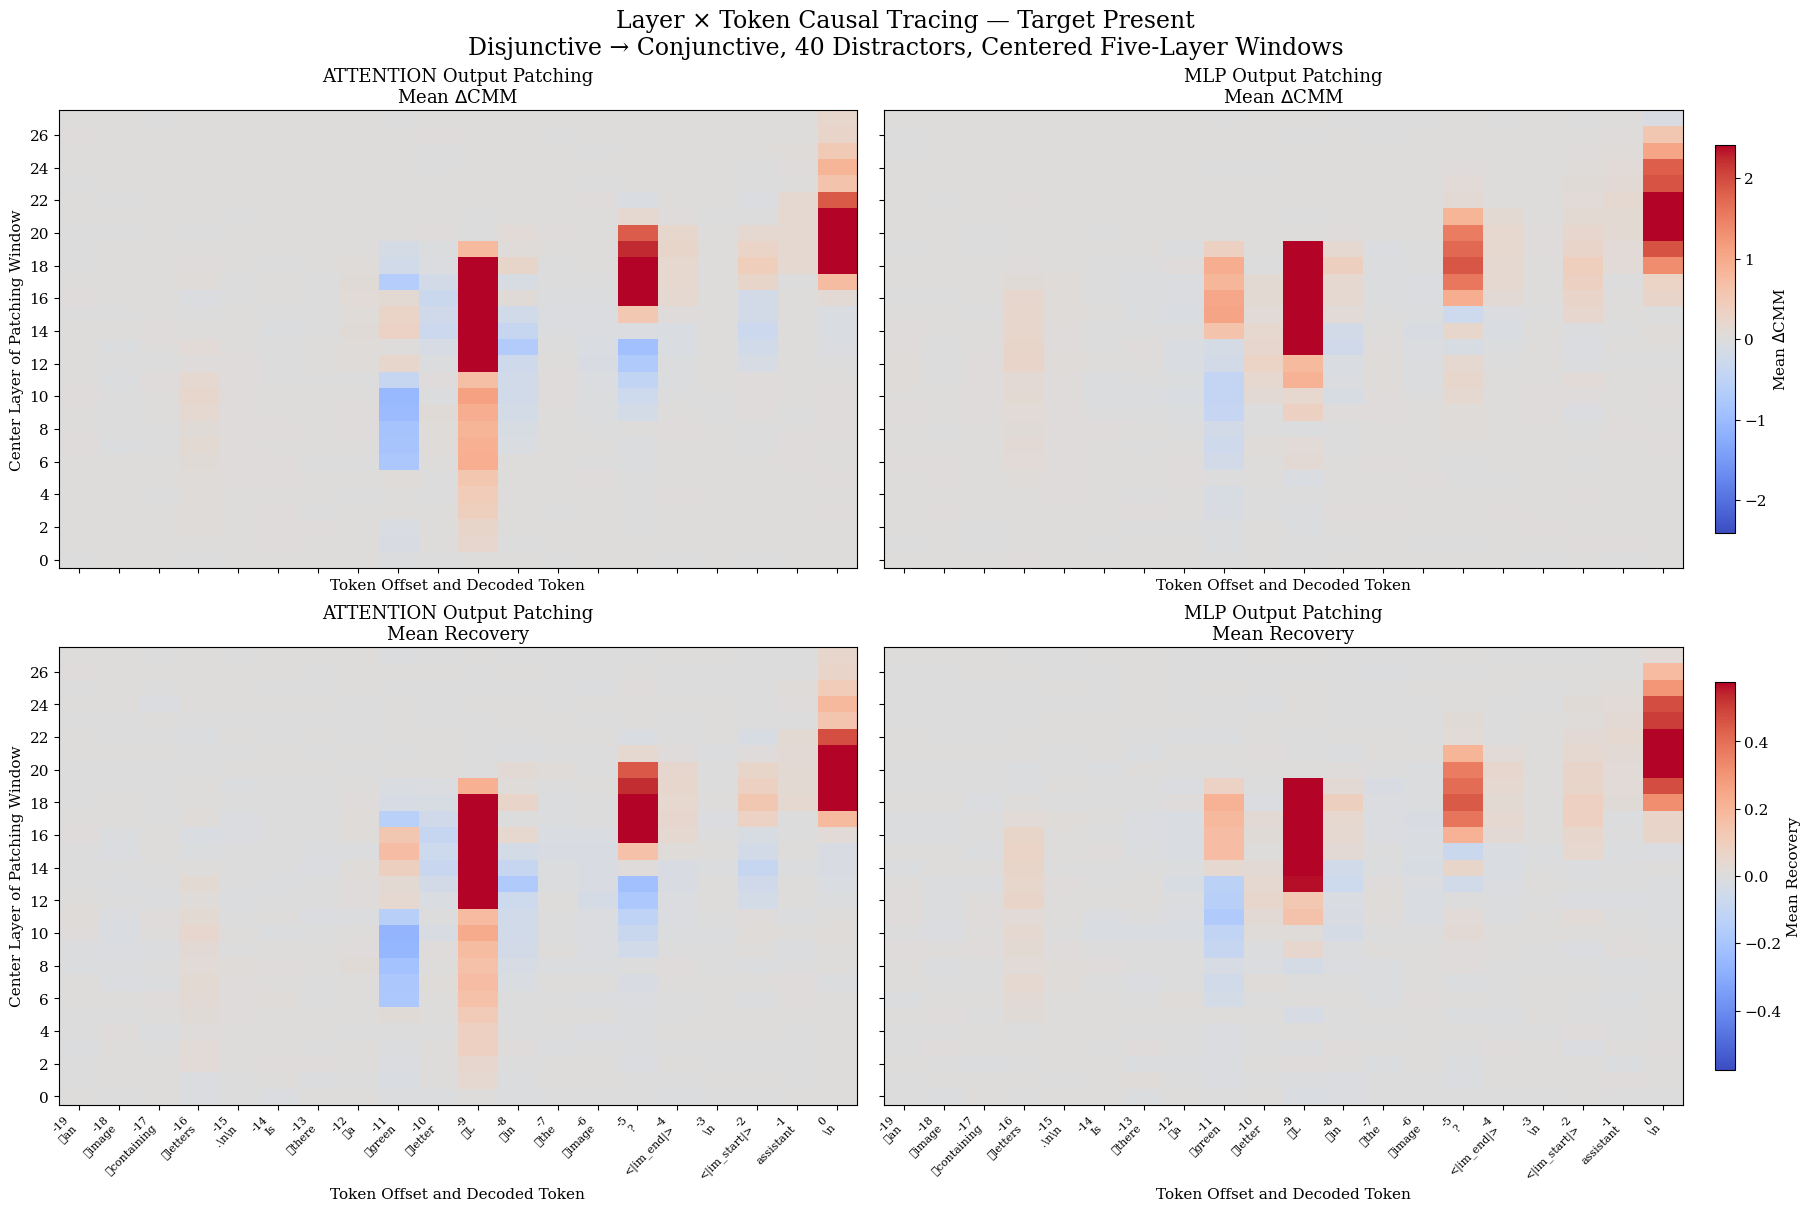

/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


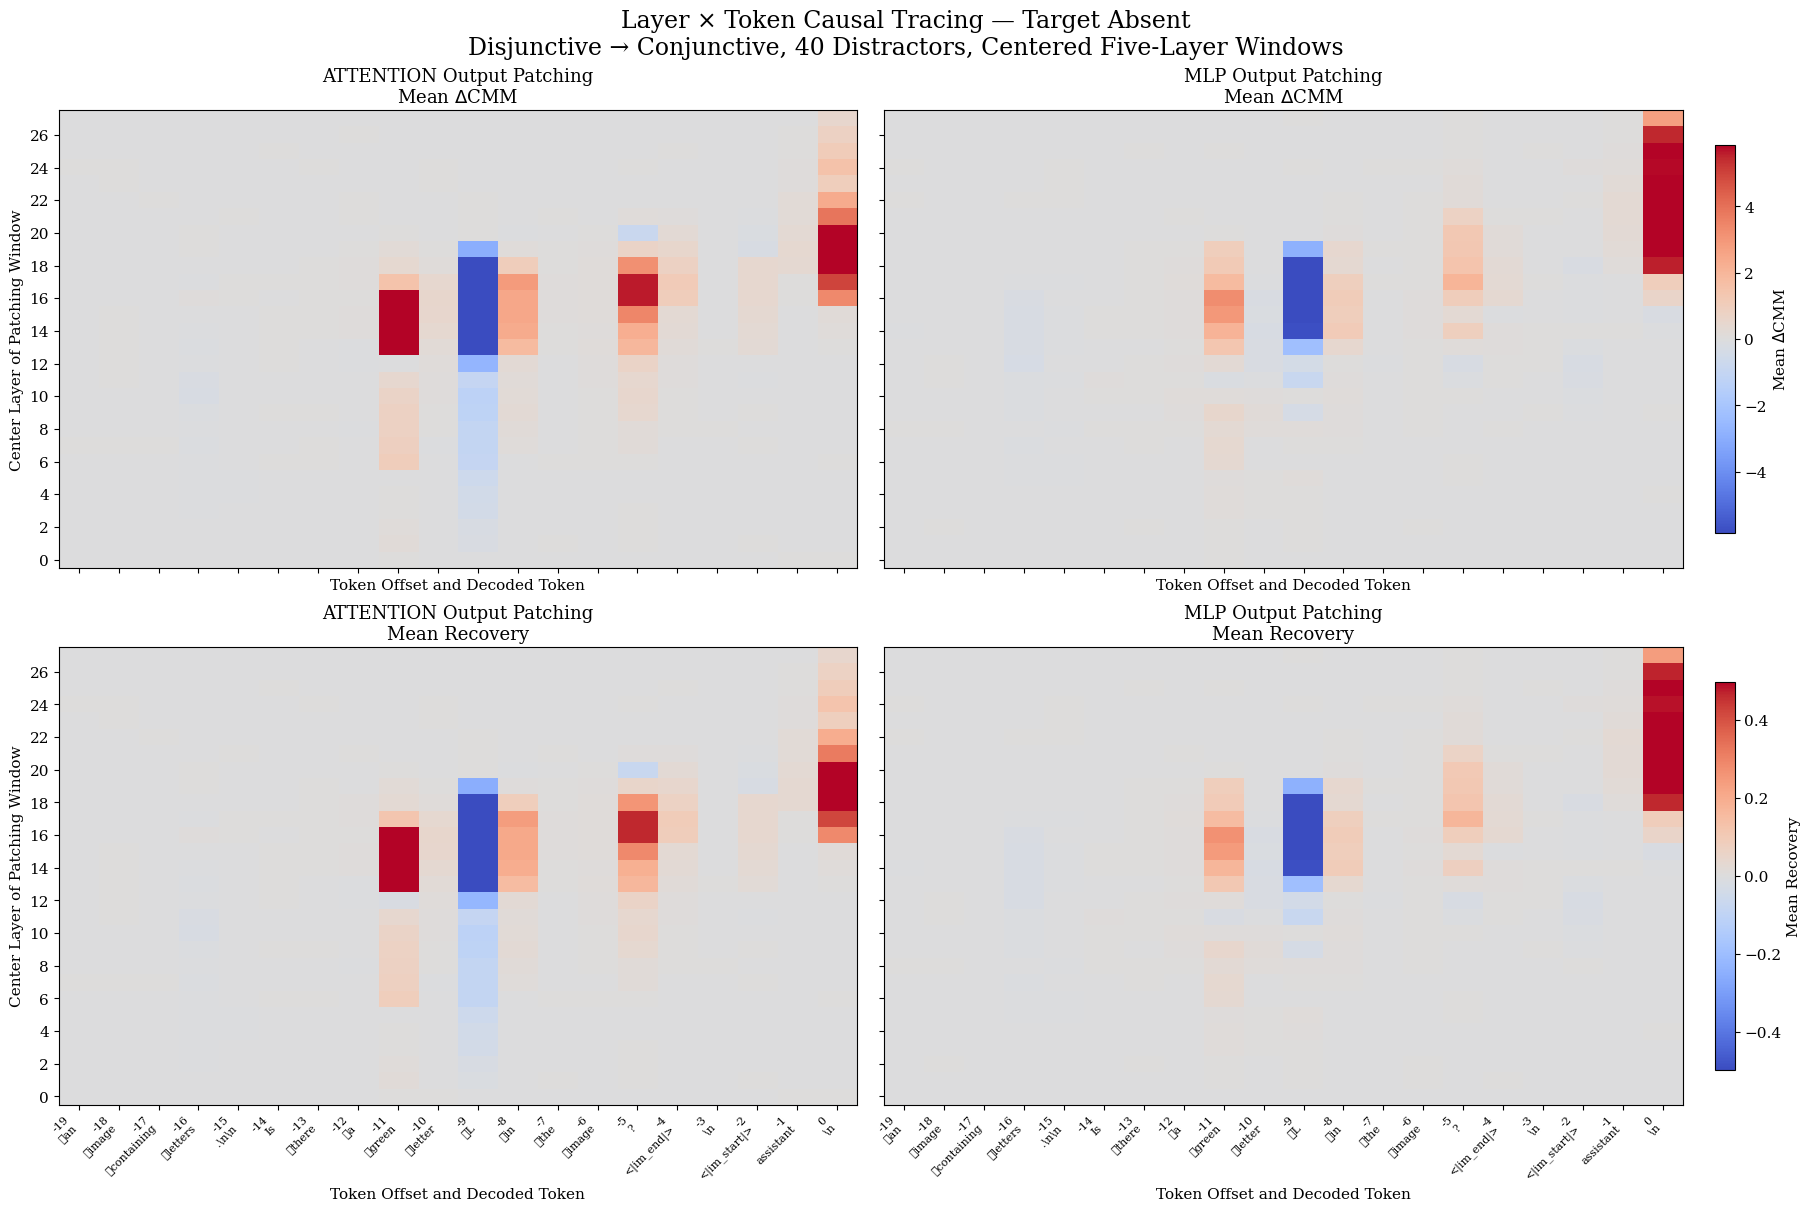

In [13]:
# Visualize causal effects over tokens and layers


RUN_NAME = "disj40_to_conj40_layer_token_components_w5"
RESULTS_DIR = "../Results"

final_path = os.path.join(RESULTS_DIR, f"{RUN_NAME}.csv")
partial_path = os.path.join(RESULTS_DIR, f"{RUN_NAME}_partial.csv")

if os.path.exists(final_path):
    path = final_path
elif os.path.exists(partial_path):
    path = partial_path
    print("Final CSV not found; using partial results.")
else:
    raise FileNotFoundError(f"Could not find:\n{final_path}\n{partial_path}")

detail_df = pd.read_csv(path).copy()

detail_df["target_present"] = (
    detail_df["target_present"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False, "1": True, "0": False})
)

detail_df["recovery"] = detail_df["recovery"].replace(
    [np.inf, -np.inf],
    np.nan,
)

group_cols = [
    "component",
    "center_layer",
    "token_offset",
    "token",
    "target_present",
]

df = (
    detail_df
    .groupby(group_cols, as_index=False)
    .agg(
        mean_delta_cmm=("delta_cmm", "mean"),
        mean_recovery=("recovery", "mean"),
    )
)

components = [
    component
    for component in ["attention", "mlp"]
    if component in df["component"].unique()
]

offsets = sorted(df["token_offset"].unique())
layers = sorted(df["center_layer"].unique())

token_map = (
    df[["token_offset", "token"]]
    .drop_duplicates("token_offset")
    .set_index("token_offset")["token"]
    .to_dict()
)


def token_label(offset):
    token = (
        str(token_map.get(offset, "?"))
        .replace(" ", "␠")
        .replace("\n", "\\n")
    )
    return f"{offset}\n{token[:12]}"


def make_matrix(data, component, metric):
    return (
        data[data["component"] == component]
        .pivot(
            index="center_layer",
            columns="token_offset",
            values=metric,
        )
        .reindex(index=layers, columns=offsets)
    )


def symmetric_vmax(matrices):
    values = np.concatenate(
        [matrix.to_numpy().ravel() for matrix in matrices]
    )
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return 1.0

    return np.nanpercentile(np.abs(values), 98)


def plot(target_present, title_label):
    subset = df[df["target_present"] == target_present].copy()

    delta_matrices = [
        make_matrix(subset, component, "mean_delta_cmm")
        for component in components
    ]
    recovery_matrices = [
        make_matrix(subset, component, "mean_recovery")
        for component in components
    ]

    delta_vmax = symmetric_vmax(delta_matrices)
    recovery_vmax = symmetric_vmax(recovery_matrices)

    fig, axes = plt.subplots(
        2,
        len(components),
        figsize=(18, 12),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    if len(components) == 1:
        axes = axes.reshape(2, 1)

    for j, component in enumerate(components):
        panels = [
            (
                delta_matrices[j],
                delta_vmax,
                r"Mean $\Delta$CMM",
            ),
            (
                recovery_matrices[j],
                recovery_vmax,
                "Mean Recovery",
            ),
        ]

        for i, (values, scale, heading) in enumerate(panels):
            ax = axes[i, j]

            ax.imshow(
                values,
                origin="lower",
                aspect="auto",
                cmap="coolwarm",
                vmin=-scale,
                vmax=scale,
            )

            ax.set_title(f"{component.upper()} Output Patching\n{heading}")
            ax.set_xticks(range(len(offsets)))
            ax.set_xticklabels(
                [token_label(offset) for offset in offsets],
                rotation=45,
                ha="right",
                fontsize=8,
            )
            ax.set_yticks(range(0, len(layers), 2))
            ax.set_yticklabels(layers[::2])
            ax.set_xlabel("Token Offset and Decoded Token")

            if j == 0:
                ax.set_ylabel("Center Layer of Patching Window")

    fig.colorbar(
        axes[0, 0].images[0],
        ax=axes[0, :].tolist(),
        shrink=0.85,
        pad=0.02,
        label=r"Mean $\Delta$CMM",
    )

    fig.colorbar(
        axes[1, 0].images[0],
        ax=axes[1, :].tolist(),
        shrink=0.85,
        pad=0.02,
        label="Mean Recovery",
    )

    fig.suptitle(
        f"Layer × Token Causal Tracing — Target {title_label}\n"
        "Disjunctive → Conjunctive, 40 Distractors, "
        "Centered Five-Layer Windows",
        fontsize=17,
    )

    plt.show()


plot(True, "Present")
plot(False, "Absent")

# Attention Head Localization (Over the "L" token)

To get the causal scores for the attention heads over th L tokens, run the following code
```
python benchmark_headpatch.py \
    --source_condition disjunctive \
    --target_condition conjunctive \
    --source_distractors 40 \
    --target_distractors 40 \
    --token_offset -9 \
    --out_path ../Results/disj40_to_conj40_headpatch_qwen_-9.csv
```
***Should take ~ 1-2 hours to run***

Visualization code splits plots into CMM scores by target present cases and target absent cases. The plot showing delta CMM is a bit more stable than recovery (recovery can be heavily influenced by denominator making it potenitally unstable)

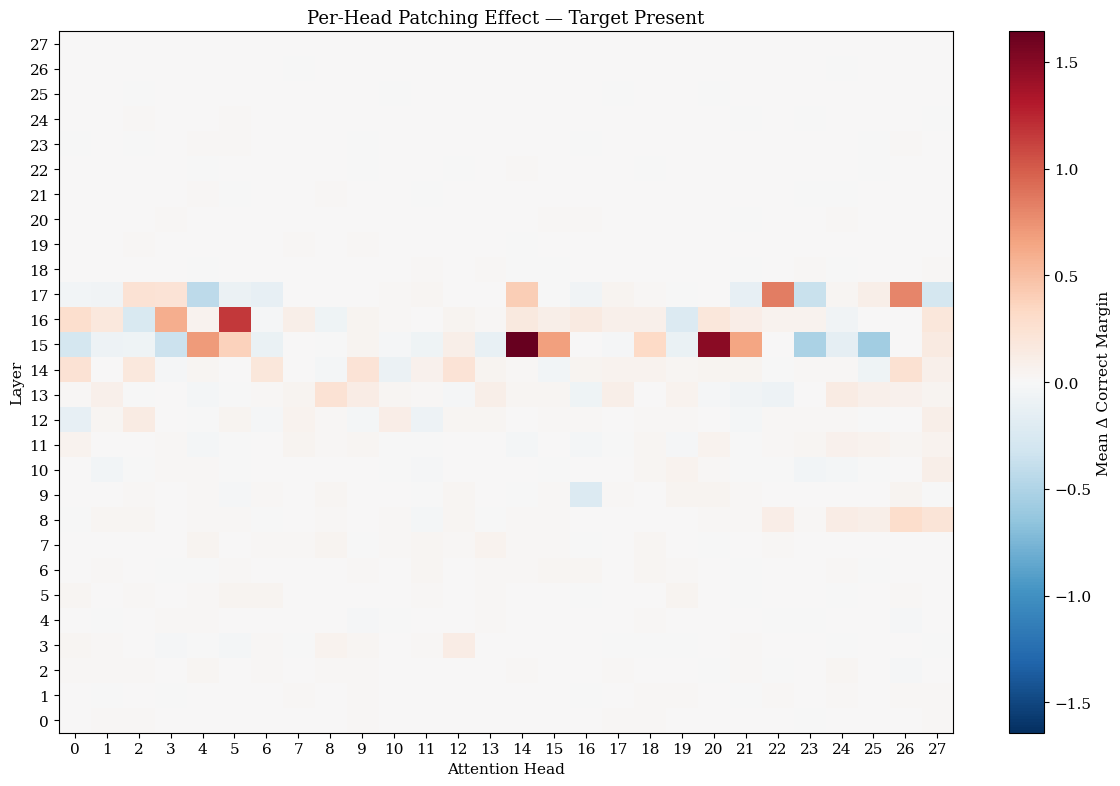

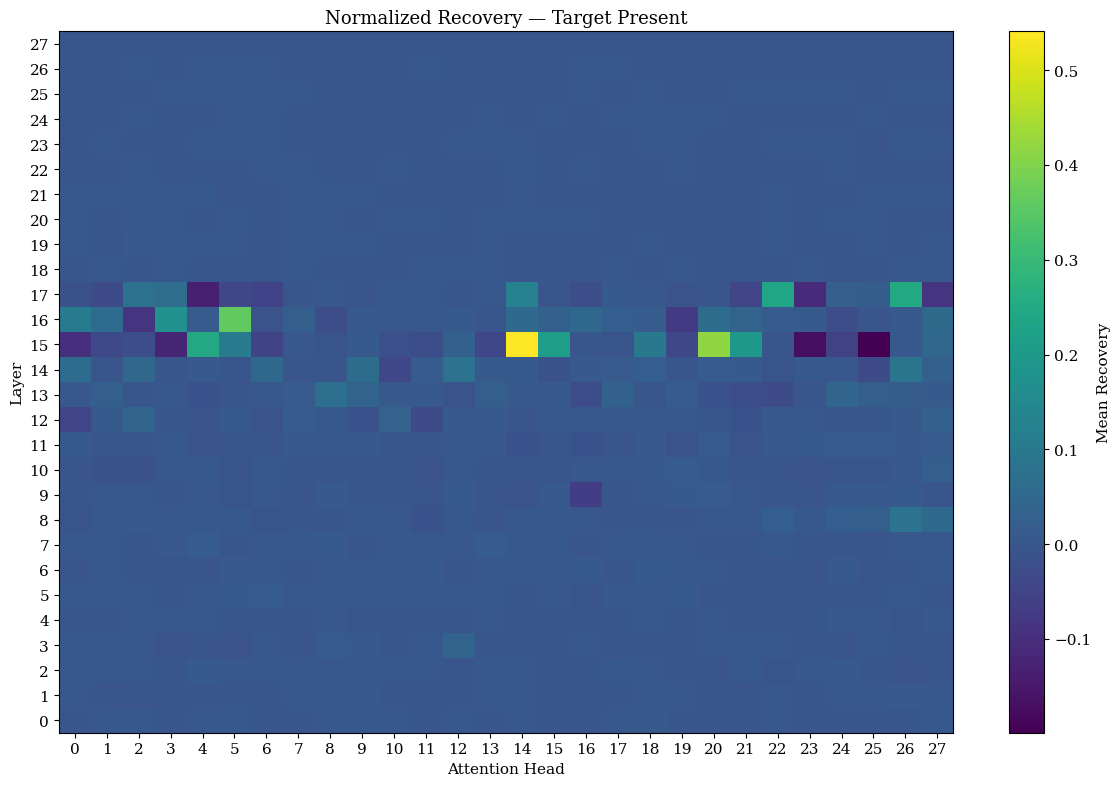

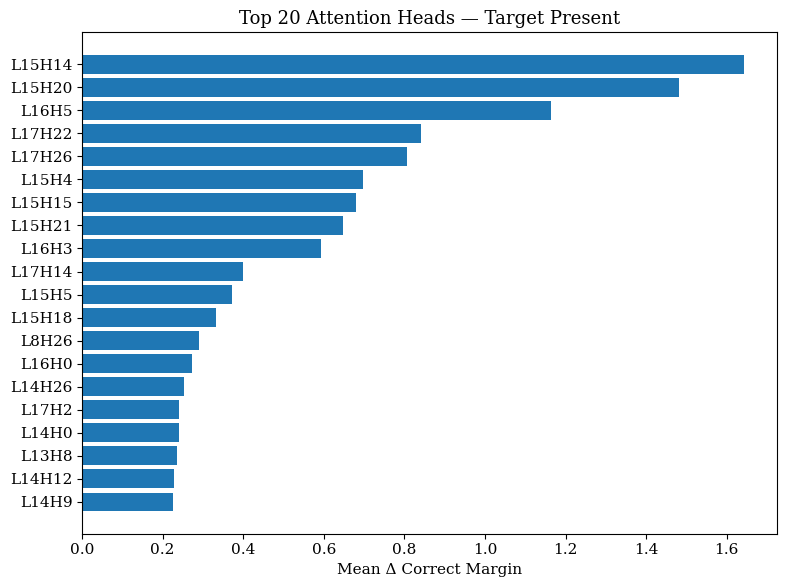


Target Present


,target_present,layer,head,delta_margin,recovery,n
1218,True,15,14,1.6425,0.540905,50
1224,True,15,20,1.4825,0.419365,50
1237,True,16,5,1.1625,0.359558,50
1282,True,17,22,0.8400,0.240262,50
1286,True,17,26,0.8075,0.251533,50
1208,True,15,4,0.6975,0.248511,50
1219,True,15,15,0.6800,0.217002,50
1225,True,15,21,0.6475,0.194328,50
1235,True,16,3,0.5925,0.173950,50
1274,True,17,14,0.4000,0.128303,50


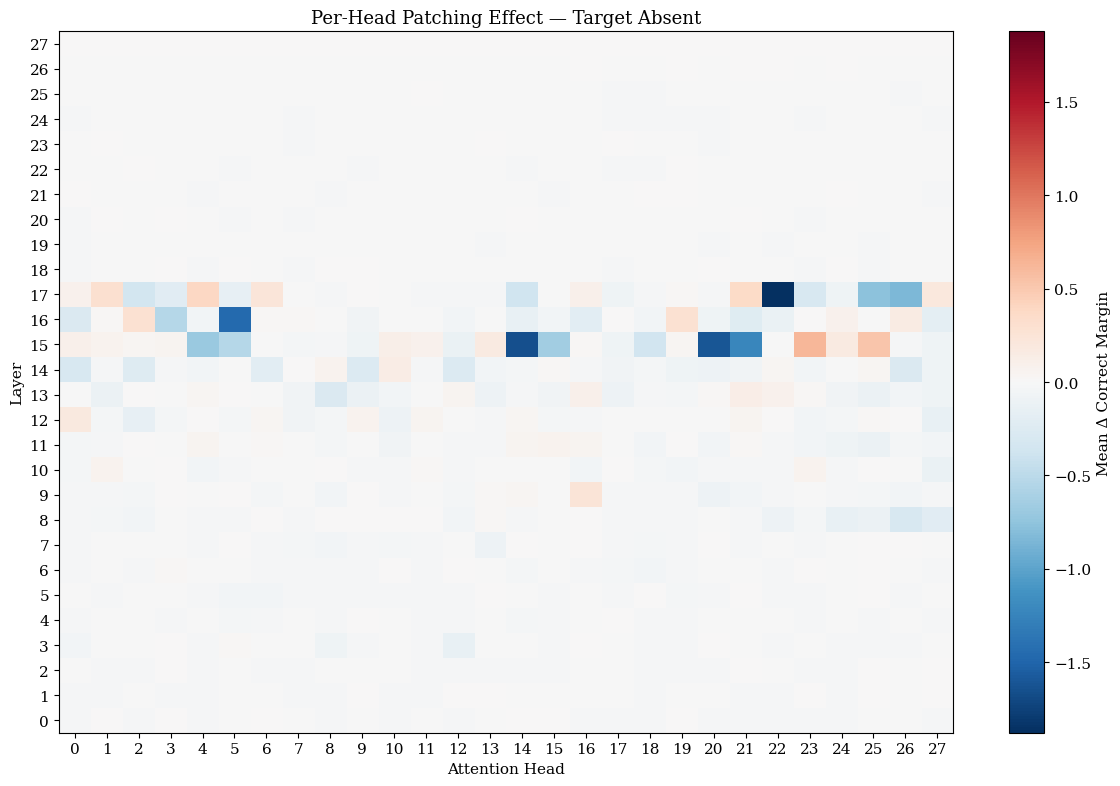

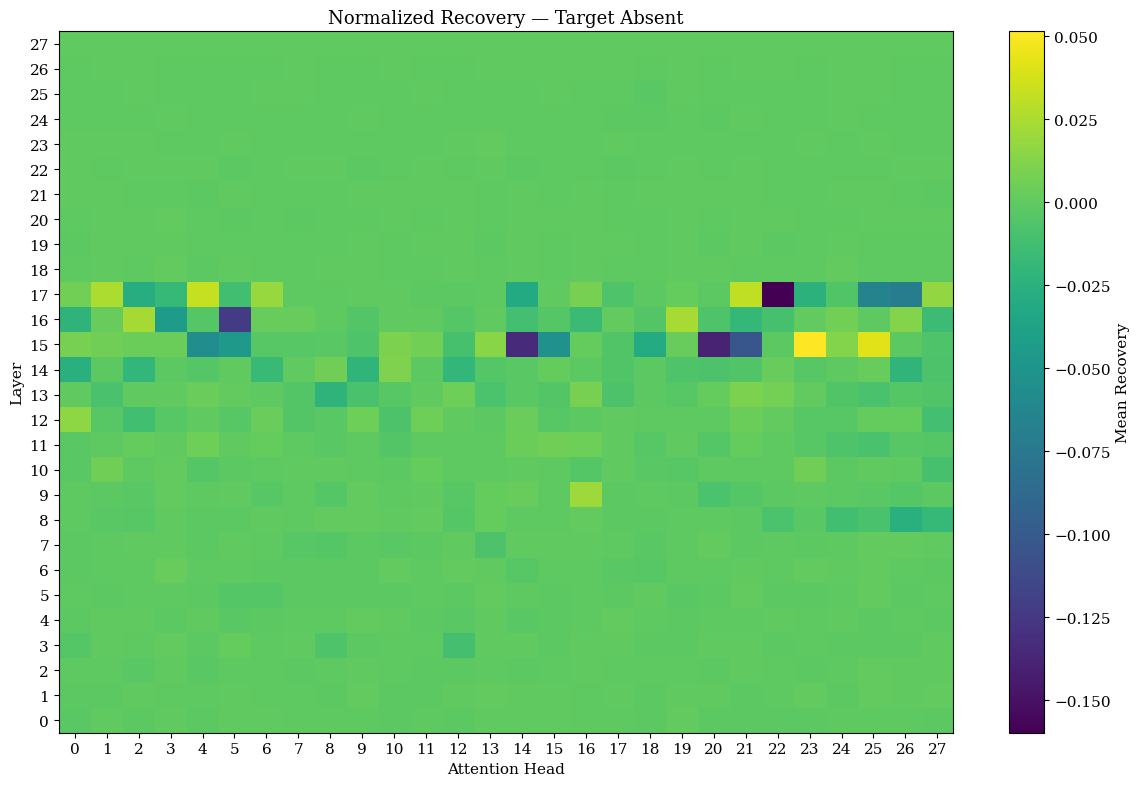

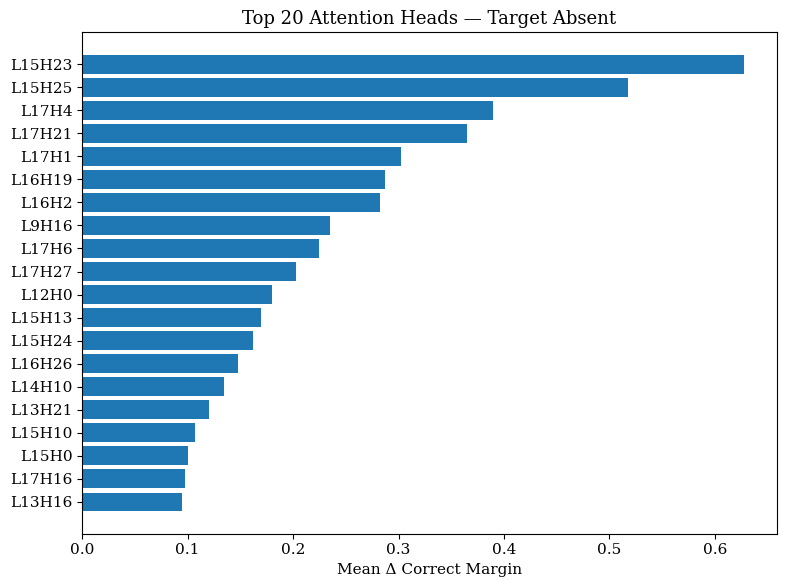


Target Absent


,target_present,layer,head,delta_margin,recovery,n
443,False,15,23,0.6275,0.051470,50
445,False,15,25,0.5175,0.042002,50
480,False,17,4,0.3900,0.032825,50
497,False,17,21,0.3650,0.031477,50
477,False,17,1,0.3025,0.025188,50
467,False,16,19,0.2875,0.023762,50
450,False,16,2,0.2825,0.022813,50
268,False,9,16,0.2350,0.020679,50
482,False,17,6,0.2250,0.018917,50
503,False,17,27,0.2025,0.017378,50


In [14]:
# Visualization of top heads

csv = "../Results/disj40_to_conj40_headpatch_qwen_-9.csv"

df = pd.read_csv(csv)

# Keep only successful patches
if "error" in df.columns:
    df = df[df["error"].isna()].copy()

# Parse target presence robustly
if df["target_present"].dtype == object:
    df["target_present"] = (
        df["target_present"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
    )

summary = (
    df.groupby(
        ["target_present", "layer", "head"],
        as_index=False,
    )
    .agg(
        delta_margin=("delta_margin", "mean"),
        recovery=("recovery", "mean"),
        n=("delta_margin", "count"),
    )
)

for target_present, condition_name in [
    (True, "Target Present"),
    (False, "Target Absent"),
]:
    condition = summary[
        summary["target_present"] == target_present
    ].copy()

    if condition.empty:
        print(f"No rows found for: {condition_name}")
        continue

    delta = (
        condition.pivot(
            index="layer",
            columns="head",
            values="delta_margin",
        )
        .sort_index()
        .sort_index(axis=1)
    )

    recovery = (
        condition.pivot(
            index="layer",
            columns="head",
            values="recovery",
        )
        .sort_index()
        .sort_index(axis=1)
    )

    # Delta-margin heatmap
    plt.figure(figsize=(12, 8))

    v = np.nanmax(np.abs(delta.values))

    plt.imshow(
        delta.values,
        origin="lower",
        aspect="auto",
        cmap="RdBu_r",
        vmin=-v,
        vmax=v,
    )

    plt.colorbar(label="Mean Δ Correct Margin")
    plt.xlabel("Attention Head")
    plt.ylabel("Layer")
    plt.title(f"Per-Head Patching Effect — {condition_name}")
    plt.xticks(np.arange(len(delta.columns)), delta.columns)
    plt.yticks(np.arange(len(delta.index)), delta.index)
    plt.tight_layout()
    plt.show()

    # Recovery heatmap
    plt.figure(figsize=(12, 8))

    plt.imshow(
        recovery.values,
        origin="lower",
        aspect="auto",
        cmap="viridis",
    )

    plt.colorbar(label="Mean Recovery")
    plt.xlabel("Attention Head")
    plt.ylabel("Layer")
    plt.title(f"Normalized Recovery — {condition_name}")
    plt.xticks(np.arange(len(recovery.columns)), recovery.columns)
    plt.yticks(np.arange(len(recovery.index)), recovery.index)
    plt.tight_layout()
    plt.show()

    # Top heads
    top = (
        condition
        .sort_values("delta_margin", ascending=False)
        .head(20)
        .copy()
    )

    labels = [
        f"L{int(layer)}H{int(head)}"
        for layer, head in zip(top["layer"], top["head"])
    ]

    plt.figure(figsize=(8, 6))
    plt.barh(labels[::-1], top["delta_margin"].values[::-1])
    plt.xlabel("Mean Δ Correct Margin")
    plt.title(f"Top 20 Attention Heads — {condition_name}")
    plt.tight_layout()
    plt.show()

    print(f"\n{condition_name}")
    display(top)

# Sparsity Experiment (What % of heads needed?)

Run the following command to get the results when patching n% of heads
```
python patch_pct_top_heads.py \
  --source_condition disjunctive \
  --target_condition conjunctive \
  --source_distractors 40 \
  --target_distractors 40 \
  --token_offset -9 \
  --head_ranking_csv ../Results/disj40_to_conj40_headpatch_qwen_-9.csv \
  --ranking_metric delta_margin \
  --rank_by_target_presence \
  --patch_percentages 0.1,0.5,1,3,5,10,20,50,100 \
  --out_path ../Results/disj40_to_conj40_cumulative_full_output_offset_-9.csv
```
***Should take ~5 min***

Visualization below patches the top heads on the target-present split for on target present examples. Similarly for target absent examples it only uses the heads ranked by target absent examples

**NOTE**: Hypothesis -- because of the atomic spatial map hypothesis, patching 100% of heads leads to 0% acuracy in target-absent examples (it thinks every object is L, therefor green Ts cause false positives)

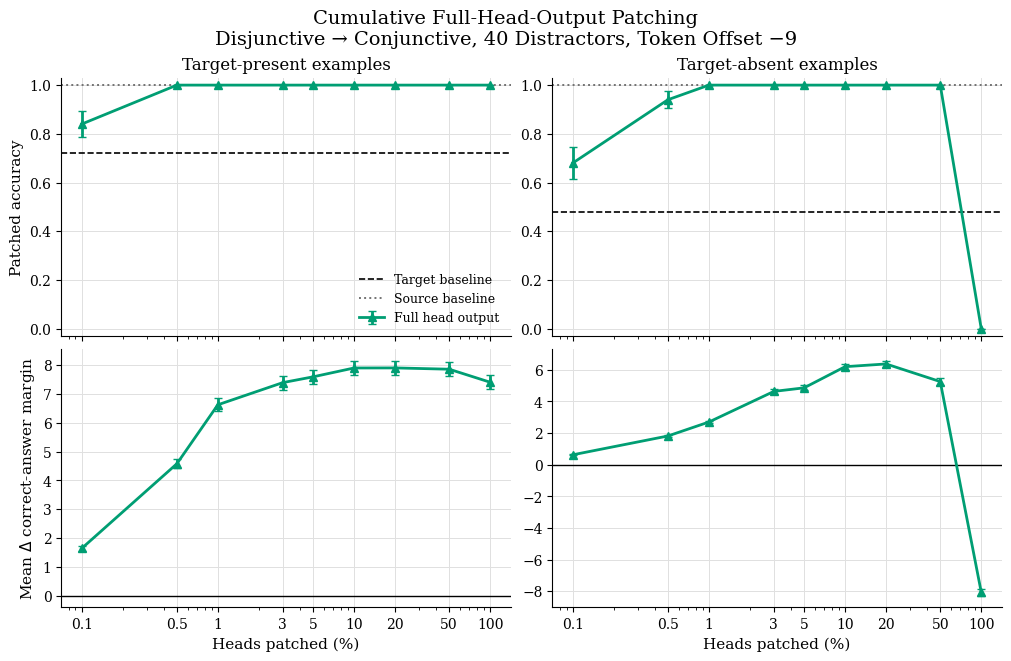

In [15]:
# Peformance when patching n% of top ranked heads

INPUT_CSV = "../Results/disj40_to_conj40_cumulative_full_output_offset_-9.csv"

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()

for col in ["target_present", "source_correct", "target_correct", "patched_correct"]:
    if df[col].dtype == object:
        df[col] = (
            df[col].astype(str).str.strip().str.lower().map(
                {"true": True, "false": False, "1": True, "0": False}
            )
        )

for col in ["patch_percentage", "delta_margin"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["patch_percentage", "target_present"])


def sem(x):
    x = pd.to_numeric(x, errors="coerce").dropna()
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0


summary = (
    df.groupby(["target_present", "patch_percentage"], as_index=False)
    .agg(
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
    )
)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.5),
    sharex=True,
    constrained_layout=True,
)

for col_idx, (target_present, title) in enumerate([
    (True, "Target-present examples"),
    (False, "Target-absent examples"),
]):
    data = (
        summary[summary["target_present"] == target_present]
        .sort_values("patch_percentage")
    )

    if data.empty:
        continue

    # Accuracy
    ax = axes[0, col_idx]
    ax.errorbar(
        data["patch_percentage"],
        data["patched_accuracy"],
        yerr=data["patched_accuracy_sem"],
        color="#009E73",
        marker="^",
        linewidth=2,
        capsize=3,
        label="Full head output",
    )
    ax.axhline(
        data["target_accuracy"].iloc[0],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Target baseline",
    )
    ax.axhline(
        data["source_accuracy"].iloc[0],
        color="0.45",
        linestyle=":",
        linewidth=1.4,
        label="Source baseline",
    )
    ax.set_title(title)
    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel("Patched accuracy" if col_idx == 0 else "")

    # Delta margin
    ax = axes[1, col_idx]
    ax.errorbar(
        data["patch_percentage"],
        data["mean_delta_margin"],
        yerr=data["delta_margin_sem"],
        color="#009E73",
        marker="^",
        linewidth=2,
        capsize=3,
    )
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Heads patched (%)")
    ax.set_ylabel(r"Mean $\Delta$ correct-answer margin" if col_idx == 0 else "")

    for row in range(2):
        ax = axes[row, col_idx]
        ax.set_xscale("log")
        ax.set_xticks(data["patch_percentage"])
        ax.set_xticklabels([f"{x:g}" for x in data["patch_percentage"]])
        ax.grid(color="0.88", linewidth=0.7)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

axes[0, 0].legend(loc="lower right", frameon=False)

fig.suptitle(
    "Cumulative Full-Head-Output Patching\n"
    "Disjunctive → Conjunctive, 40 Distractors, Token Offset −9",
    fontsize=14,
)

plt.show()

# PCA of top heads

Run the following command to extract activations/run PCA
```
python extract_ranked_head_outputs_pca.py \
  --ranking_csv ../Results/disj40_to_conj40_headpatch_qwen_-9.csv \
  --ranking_metric delta_margin \
  --ranking_target_present true \
  --top_k 8 \
  --distractors 40 \
  --token_offset -9 \
  --target_presence all \
  --pair_filter all \
  --out_dir ../Results/disj40_to_conj40_head_outputs_top8_present_ranked_offset_-9
```
***Expected to take ~1 min***

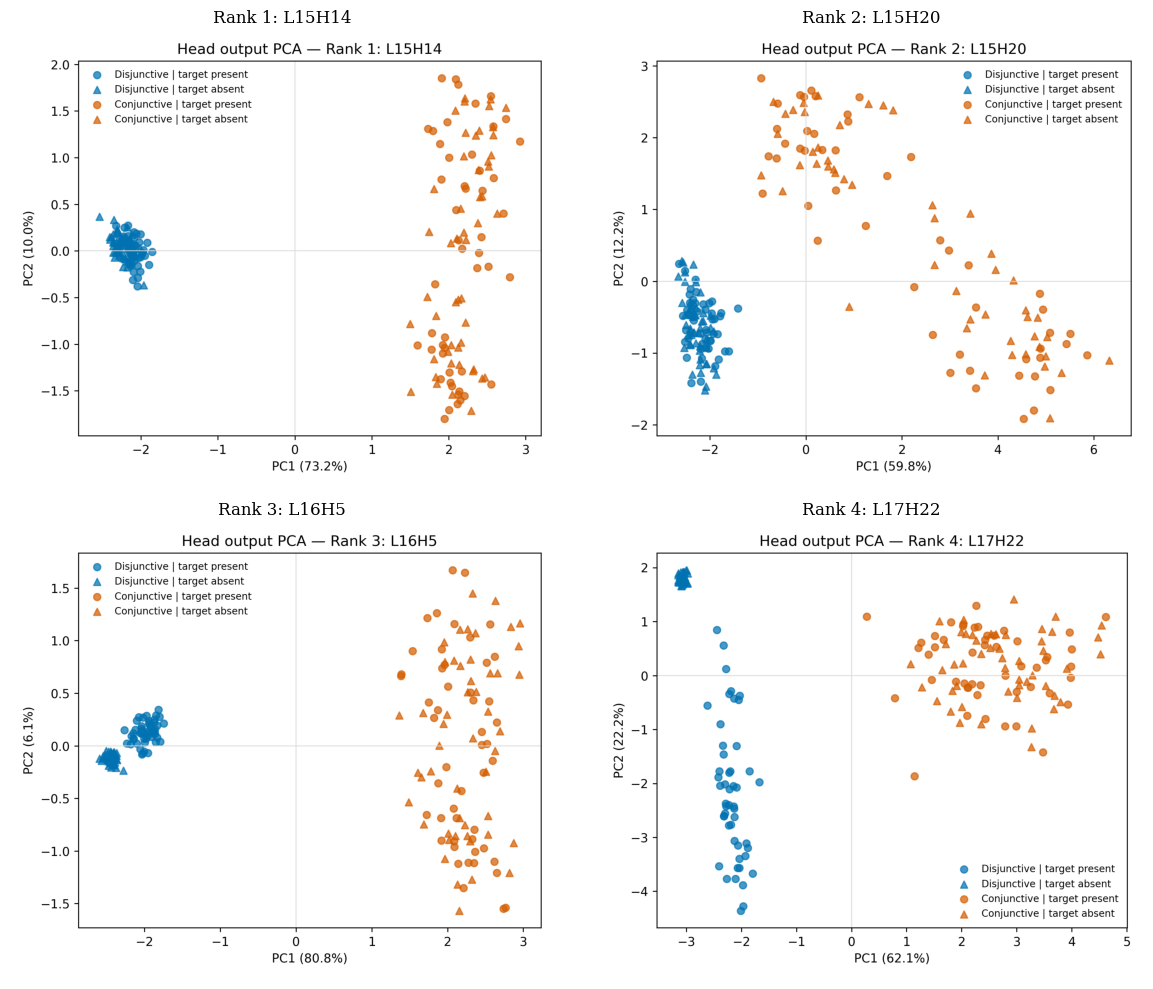

In [22]:
# PCA of top 4 causal heads (on target present split)

PCA_DIR = Path(
    "../Results/disj40_to_conj40_head_outputs_top8_present_ranked_offset_-9"
)

selected = (
    pd.read_csv(PCA_DIR / "selected_heads.csv")
    .sort_values("rank")
    .head(4)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, row in zip(axes, selected.itertuples(index=False)):
    plot_path = PCA_DIR / f"pca_L{row.layer}H{row.head}.png"

    ax.imshow(Image.open(plot_path))
    ax.set_title(
        f"Rank {row.rank}: L{row.layer}H{row.head}",
        fontsize=12,
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# Minimal Pair Swap Experiment (Causal Evidence For Spatial Maps)

Replicate Experiment in section 3.4.1 of writeup

After running the benchmark to verify baseline behavior, run the below command:

```bash
python mp_s_patch_pct_top_attention_components.py \
  --dataset MP_S \
  --token_offset -9 \
  --head_ranking_csv ../Results/disj40_to_conj40_headpatch_qwen_-9.csv \
  --ranking_metric delta_margin \
  --rank_by_target_presence \
  --patch_percentages 0.1,0.2,0.5,1,10,25,50,100 \
  --out_path ../Results/mp_s_present_ranked_heads_offset_-9.csv
```

***Should take ~10 min***

For unpaired counter factual sourcing (as a control to verify spatial importance) run the following

```bash
python mp_s_patch_pct_top_attention_components.py \
  --dataset MP_S \
  --token_offset -9 \
  --head_ranking_csv ../Results/disj40_to_conj40_headpatch_qwen_-9.csv \
  --ranking_metric delta_margin \
  --rank_by_target_presence \
  --patch_percentages 0.1,0.2,0.5,1,10,25,50,100 \
  --unpaired_counterfactuals \
  --out_path ../Results/mp_s_present_ranked_heads_unpaired_offset_-9.csv
```
***Should take ~10 min***

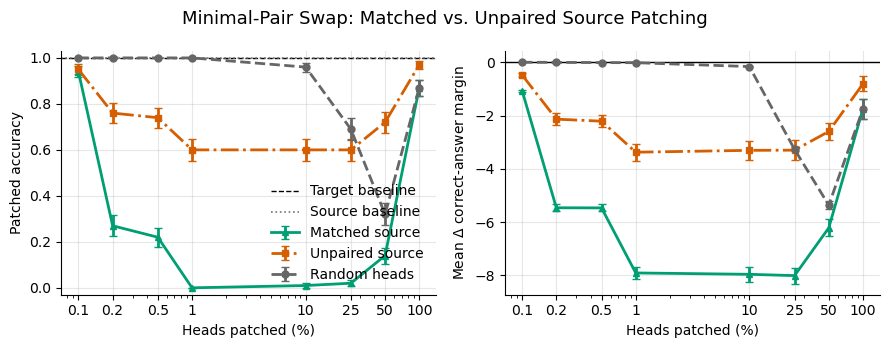

In [4]:
# Performance when patching n% of heads

MATCHED_CSV = "../Results/mp_s_present_ranked_heads_offset_-9.csv"
UNPAIRED_CSV = "../Results/mp_s_present_ranked_heads_unpaired_offset_-9.csv"


def load_and_summarize(path, pairing):
    df = pd.read_csv(path).copy()

    if "error" in df.columns:
        df = df[df["error"].isna()].copy()

    for col in ["source_correct", "target_correct", "patched_correct"]:
        if df[col].dtype == object:
            df[col] = (
                df[col].astype(str).str.strip().str.lower().map(
                    {"true": True, "false": False, "1": True, "0": False}
                )
            )

    for col in ["patch_percentage", "delta_margin"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    def sem(x):
        x = pd.to_numeric(x, errors="coerce").dropna()
        return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0

    summary = (
        df.groupby(["selection_type", "patch_percentage"], as_index=False)
        .agg(
            source_accuracy=("source_correct", "mean"),
            target_accuracy=("target_correct", "mean"),
            patched_accuracy=("patched_correct", "mean"),
            patched_accuracy_sem=("patched_correct", sem),
            mean_delta_margin=("delta_margin", "mean"),
            delta_margin_sem=("delta_margin", sem),
        )
    )

    summary["source_pairing"] = pairing
    return summary


plot_df = pd.concat(
    [
        load_and_summarize(MATCHED_CSV, "Matched source"),
        load_and_summarize(UNPAIRED_CSV, "Unpaired source"),
    ],
    ignore_index=True,
)

styles = {
    ("ranked", "Matched source"): {
        "color": "#009E73",
        "marker": "^",
        "linestyle": "-",
        "label": "Matched source",
    },
    ("ranked", "Unpaired source"): {
        "color": "#D55E00",
        "marker": "s",
        "linestyle": "-.",
        "label": "Unpaired source",
    },
    ("random", "Matched source"): {
        "color": "#666666",
        "marker": "o",
        "linestyle": "--",
        "label": "Random heads",
    },
}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

for ax, metric, error, ylabel in [
    (
        axes[0],
        "patched_accuracy",
        "patched_accuracy_sem",
        "Patched accuracy",
    ),
    (
        axes[1],
        "mean_delta_margin",
        "delta_margin_sem",
        r"Mean $\Delta$ correct-answer margin",
    ),
]:
    for (selection_type, pairing), style in styles.items():
        data = plot_df[
            (plot_df["selection_type"] == selection_type)
            & (plot_df["source_pairing"] == pairing)
        ].sort_values("patch_percentage")

        if data.empty:
            continue

        ax.errorbar(
            data["patch_percentage"],
            data[metric],
            yerr=data[error],
            color=style["color"],
            marker=style["marker"],
            linestyle=style["linestyle"],
            linewidth=2,
            markersize=5,
            capsize=3,
            label=style["label"],
        )

    ax.set_xscale("log")
    ticks = sorted(plot_df["patch_percentage"].dropna().unique())
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{tick:g}" for tick in ticks])
    ax.set_xlabel("Heads patched (%)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylim(-0.03, 1.03)

target_baseline = plot_df["target_accuracy"].iloc[0]
source_baseline = plot_df["source_accuracy"].iloc[0]

axes[0].axhline(
    target_baseline,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Target baseline",
)
axes[0].axhline(
    source_baseline,
    color="0.45",
    linestyle=":",
    linewidth=1.2,
    label="Source baseline",
)
axes[1].axhline(0, color="black", linewidth=1)

axes[0].legend(frameon=False, loc="lower right")
fig.suptitle(
    "Minimal-Pair Swap: Matched vs. Unpaired Source Patching",
    fontsize=13,
)

plt.tight_layout()
plt.show()